In [1]:
import json
import pandas as pd
from typing import List, Dict, Any
from pydantic import BaseModel
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib_venn import venn2


In [2]:
class RefactoringAction(BaseModel):
    name: str = ""
    target: str = ""
    to: str = ""
    where: str = ""
    taggedValue: str
    scalingFactor: str

    def encode(self) -> str:
        if self.name.lower() == 'clone':
            return f"{self.name}___{self.target}__Cloned-Node_{self.to}__{self.where}"
        return f"{self.name}___{self.target}__{self.to}__{self.where}"

class Solution(BaseModel):
    objectives: Dict[str, Any]
    consideredObjectives: Dict[str, Any]
    refactoring: List[RefactoringAction]
    solID: int

    def encode(self) -> List[str]:
      return {
        "solID": self.solID,
        "actions": [action.encode() for action in self.refactoring],
        "objectives": self.consideredObjectives
      }

class Population(BaseModel):
    solutions: List[Solution]
    independentRun: int
    iteration: int

    def to_dataframe(self, n_actions=4) -> pd.DataFrame:
        data = [sol.encode() for sol in self.solutions]
        # Flatten refactoring actions for each solution
        # for entry in data:
        #   actions = entry.pop("actions")
        #   for i in range(n_actions):
        #       if i < len(actions):
        #           entry[f"action_{i+1}"] = actions[i]
        #       else:
        #           entry[f"action_{i+1}"] = None
        # Flatten objectives dictionary for each solution
        for entry in data:
          objectives = entry.pop("objectives")
          for obj_key, obj_value in objectives.items():
              entry[obj_key] = obj_value
        return pd.DataFrame(data)

    def get_vocabulary(self) -> List[str]:
        vocabulary = set()
        for sol in self.solutions:
            for action in sol.refactoring:
                vocabulary.add(action.encode())
        return list(vocabulary)

class Experiment(BaseModel):
    population: List[Solution]
    pareto: List[Population]
    superPareto: List[Population]
    # For now, we are skipping the configuration part
    configuration: Dict[str, Any]


In [3]:
# JSON_FILENAME = "./easier_pop_json/experiment.json"
JSON_FILENAME = "./nsgaii-ccm-eval-102-surrogate-false/run1/experiment.json"


with open(JSON_FILENAME, 'r') as json_file:
    experiment_dict = json.load(json_file)

# experiment_dict
experiment = Experiment(**experiment_dict)

In [4]:
# JSON_FILENAME = "./easier_pop_json/population__1.json"
# JSON_FILENAME = "./easier_pop_json/population__5.json"
# JSON_FILENAME = "./nsgaii-ccm-eval-102-surrogate-false/run3/population__1.json"
# JSON_FILENAME = "./nsgaii-ttbs-eval-102-surrogate-false/run3/population__1.json"
# JSON_FILENAME = "./nsgaii-ttbs-eval-102-surrogate-50_seq/run3/population__1.json"
JSON_FILENAME = "./nsgaii-ttbs-eval-102-surrogate-false/run3/population__1.json"

with open(JSON_FILENAME, 'r') as json_file:
    population_dict = json.load(json_file)

population_dict
population1 = Population(**population_dict)

In [5]:
df1 = population1.to_dataframe()
print(df1.shape)
df1

(12, 13)


,solID,actions,perfq,pricePerScenario__Login_job_class,pricePerScenario__Rebook a ticket_job_class,pas,price,changes,energyPerScenario__Login_job_class,power,energyPerScenario__Update user details_job_class,pricePerScenario__Update user details_job_class,energyPerScenario__Rebook a ticket_job_class
0,11,[clone___continer-route-plan_d2.2xlarge__Clone...,-0.213648,1.174000,0.279300,3.0,3.1325,11.11,101.507004,149.449999,13.815462,0.035700,34.127530
1,9,[moncnn___updateUser__New-Component_xwtynxbqnk...,-0.130328,0.742800,0.279300,3.0,1.8380,5.58,47.764150,96.682349,14.791045,0.035700,34.127163
2,7,[mcnn___Order-other__New-Node_t2.medium_afenbs...,-0.130378,0.742800,0.063400,4.0,1.9331,13.48,47.764108,91.216916,25.122922,0.130800,18.329889
3,6,[moncnn___updateUser__New-Component_hjyrnvqoyw...,-0.119405,0.495200,0.374400,4.0,1.9014,11.52,38.797402,92.233067,13.815462,0.035700,39.620166
4,5,[mcnn___Rebook__New-Node_m6i.xlarge_qcizugsmfx...,-0.178392,0.495200,0.255586,2.0,1.8737,11.74,38.794164,82.269820,13.014199,0.126814,30.461474
5,3,[moncnn___login__New-Component_bhflacgxsr__New...,-0.105779,0.360852,0.279300,4.0,1.9905,6.18,27.222409,79.570179,18.220244,0.138348,34.127530
6,1,[mcnn___Route-plan__New-Node_t2.medium_fozvewg...,-0.133039,0.495200,0.279300,3.0,1.6855,10.07,38.790563,86.733158,13.815462,0.035700,34.127163
7,29,[clone___continer-route-plan_d2.2xlarge__Clone...,-0.213648,1.174000,0.279300,3.0,3.1325,11.11,101.507004,149.449999,13.815462,0.035700,34.127530
8,25,[moncnn___updateUser__New-Component_hjyrnvqoyw...,-0.119405,0.495200,0.374400,4.0,1.9014,11.52,38.797402,92.233067,13.815462,0.035700,39.620166
9,22,"[moc___findAll__Rebook__, moc___rebook__Route-...",-0.109902,0.495200,0.710800,2.0,1.6538,8.11,38.790563,113.881352,20.166353,0.067400,54.924469


In [6]:
vocab = population1.get_vocabulary()
print(len(vocab))
vocab

30


['moncnn___updateUser__New-Component_pnytowkttl__New-Node_d2.2xlarge_xehxathiln',
 'moncnn___modify__New-Component_mzkcbpdohi__New-Node_m6i.xlarge_wgpwiwgdqm',
 'moc___verify__Route-plan__',
 'mcnn___Rebook__New-Node_m6i.xlarge_qcizugsmfx__',
 'moncnn___verify__New-Component_olxhongfql__New-Node_m6i.xlarge_axshxcqjmq',
 'clone___container-order-other_m5ad.xlarge__Cloned-Node_container-order-other_m5ad.xlarge_jhcjydnlkm__',
 'mcnn___Station__New-Node_m6i.xlarge_fthquzdduz__',
 'moncnn___verify__New-Component_krvlkktvyc__New-Node_m6i.xlarge_uelilyjgqd',
 'clone___continer-route-plan_d2.2xlarge__Cloned-Node_continer-route-plan_d2.2xlarge_ggaesqufzz__',
 'moncnn___login__New-Component_bhflacgxsr__New-Node_m6i.xlarge_jtjvukpvxx',
 'moncnn___updateUser__New-Component_xwtynxbqnk__New-Node_m6i.xlarge_autffezygl',
 'mcnn___Verification__New-Node_d2.2xlarge_mjadtoysps__',
 'mcnn___Route-plan__New-Node_t2.medium_fozvewgcgv__',
 'mcnn___Rebook__New-Node_m6i.xlarge_pbnbatvfhp__',
 'moc___updateUser

In [7]:
df1

,solID,actions,perfq,pricePerScenario__Login_job_class,pricePerScenario__Rebook a ticket_job_class,pas,price,changes,energyPerScenario__Login_job_class,power,energyPerScenario__Update user details_job_class,pricePerScenario__Update user details_job_class,energyPerScenario__Rebook a ticket_job_class
0,11,[clone___continer-route-plan_d2.2xlarge__Clone...,-0.213648,1.174000,0.279300,3.0,3.1325,11.11,101.507004,149.449999,13.815462,0.035700,34.127530
1,9,[moncnn___updateUser__New-Component_xwtynxbqnk...,-0.130328,0.742800,0.279300,3.0,1.8380,5.58,47.764150,96.682349,14.791045,0.035700,34.127163
2,7,[mcnn___Order-other__New-Node_t2.medium_afenbs...,-0.130378,0.742800,0.063400,4.0,1.9331,13.48,47.764108,91.216916,25.122922,0.130800,18.329889
3,6,[moncnn___updateUser__New-Component_hjyrnvqoyw...,-0.119405,0.495200,0.374400,4.0,1.9014,11.52,38.797402,92.233067,13.815462,0.035700,39.620166
4,5,[mcnn___Rebook__New-Node_m6i.xlarge_qcizugsmfx...,-0.178392,0.495200,0.255586,2.0,1.8737,11.74,38.794164,82.269820,13.014199,0.126814,30.461474
5,3,[moncnn___login__New-Component_bhflacgxsr__New...,-0.105779,0.360852,0.279300,4.0,1.9905,6.18,27.222409,79.570179,18.220244,0.138348,34.127530
6,1,[mcnn___Route-plan__New-Node_t2.medium_fozvewg...,-0.133039,0.495200,0.279300,3.0,1.6855,10.07,38.790563,86.733158,13.815462,0.035700,34.127163
7,29,[clone___continer-route-plan_d2.2xlarge__Clone...,-0.213648,1.174000,0.279300,3.0,3.1325,11.11,101.507004,149.449999,13.815462,0.035700,34.127530
8,25,[moncnn___updateUser__New-Component_hjyrnvqoyw...,-0.119405,0.495200,0.374400,4.0,1.9014,11.52,38.797402,92.233067,13.815462,0.035700,39.620166
9,22,"[moc___findAll__Rebook__, moc___rebook__Route-...",-0.109902,0.495200,0.710800,2.0,1.6538,8.11,38.790563,113.881352,20.166353,0.067400,54.924469


In [8]:
# df1.columns

---

In [9]:
ttbs_objectives_seq = ['perfq', 'pas', 'price', 'reliability', 'changes', 'power', 'energy']
ttbs_objectives_std = ['perfq', 'pricePerScenario__Login_job_class',
       'pricePerScenario__Rebook a ticket_job_class', 'pas', 'price',
       'changes', 'energyPerScenario__Login_job_class', 'power',
       'energyPerScenario__Update user details_job_class',
       'pricePerScenario__Update user details_job_class',
       'energyPerScenario__Rebook a ticket_job_class']


ccm_objectives = ['perfq', 'pas',
       'energyPerScenario__ReceivedOrderedProducts_job_class',
       'energyPerScenario__ProcessSale_job_class', 'price',
       'pricePerScenario__ProcessSale_job_class', 'changes',
       'pricePerScenario__ReceivedOrderedProducts_job_class', 'power',
       'energyPerScenario__ShowDeliveryReports_job_class',
       'pricePerScenario__ShowDeliveryReports_job_class']

In [10]:
def melt_actions_per_position(df1: pd.DataFrame, action_types=['redo', 'move', 'clone', 'motn'], n_actions=4) -> pd.DataFrame:
    df = df1.copy()
    # In column 'actions', create one colum per (action,position) pair (up to 4 actions x 4 positions), with the count of each action type that position
    # The positions are determined by the order in which the actions appear in the list (0 to 3)
    for action_type in action_types:
        for position in range(n_actions):
            col_name = f"{action_type}_pos{position}"
            df[col_name] = df['actions'].apply(
                lambda actions: sum(1 for idx, action in enumerate(actions) if action == action_type and idx == position)
            )
    df.drop('actions', axis=1, inplace=True)
    df.drop('solID', axis=1, inplace=True)

    # Now convert the above dataframe into the following schema of columns: 'run', 'population', 'position', 'action_type'
    melted_df = df.melt(id_vars=['run', 'population'], var_name='action_position', value_name='count')
    # Split 'action_position' into 'action_type' and 'position'
    melted_df[['action_type', 'position']] = melted_df['action_position'].str.split('_pos', expand=True)
    melted_df.drop('action_position', axis=1, inplace=True)
    # Remove all rows where 'count' is 0
    melted_df = melted_df[melted_df['count'] > 0]
    melted_df.drop('count', axis=1, inplace=True)
    
    return melted_df    

def collect_actions_per_run(run: int, n_populations: int, path: str, objectives, 
                            algorithm=None, init_population=0, process_actions=True,
                            action_types=['redo', 'move', 'clone', 'motn']) -> pd.DataFrame:
    
    list_of_dfs = []
    for i in range(init_population, n_populations):
        json_filename = f"{path}/run{run}/population__{i+1}.json"
        with open(json_filename, 'r') as json_file:
            population_dict = json.load(json_file)
        population = Population(**population_dict)
        df = population.to_dataframe()
        df['run'] = run
        df['population'] = i+1
        # print(f"Run {run}, Population {i+1}, Shape: {df.shape}")
        df.drop(objectives, axis=1, inplace=True)
        
        if process_actions:
            # In column 'actions', split by '__' and keep only the first part (the action name)
            df['actions'] = df['actions'].apply(lambda x: [action.split('__')[0] for action in x])
            # In column 'actions', perform the following substitutions:
            # 'mcnn' -> 'redo'
            # 'moc' -> 'move'   
            # 'moncnn' -> 'motn'
            df['actions'] = df['actions'].apply(
                lambda actions: [
                    'redo' if action == 'mcnn' else 'move' if action == 'moc' else 'motn' if action == 'moncnn' else action
                    for action in actions
                ]
            )
            df = melt_actions_per_position(df, action_types=action_types)
        list_of_dfs.append(df)
        
    final_df = pd.concat(list_of_dfs, ignore_index=True)
    if algorithm is not None:
        final_df['algorithm'] = algorithm
    else:
        final_df['algorithm'] = path.split('/')[1]
    
    return final_df

def collect_actions_all_runs(n_runs: int, n_populations: int, path: str, objectives,
                             algorithm = None, init_population=0, process_actions=True,
                             action_types=['redo', 'move', 'clone', 'motn']) -> pd.DataFrame:
    
    list_of_dfs = []
    for run in range(1, n_runs + 1):
        df_run = collect_actions_per_run(run=run, n_populations=n_populations, objectives=objectives,
                                         init_population=init_population, process_actions=process_actions,
                                         path=path, algorithm=algorithm, action_types=action_types)
        list_of_dfs.append(df_run)
        
    final_df = pd.concat(list_of_dfs, ignore_index=True)
    return final_df

In [11]:
ref_types = ['redo', 'move', 'clone', 'motn']
colors = ['indianred', 'lightgreen', 'deepskyblue', 'orange']

def plot_stacked_actions_per_position(df, action_types, colors, title='Percentage of Refactoring Actions per Position', 
                                       figsize=(10, 6), label_threshold=0.02, ylabel='Percentage'):
    """
    Create a stacked bar chart showing the percentage distribution of action types per position.
    
    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame with 'position' and 'action_type' columns
    action_types : list
        List of action types in desired order (e.g., ['redo', 'move', 'clone', 'motn'])
    colors : list
        List of colors corresponding to each action type
    title : str
        Title of the chart
    figsize : tuple
        Figure size (width, height)
    label_threshold : float
        Minimum bar segment percentage to display label (default: 0.02 for 2%)
    ylabel : str
        Label for y-axis
    
    Returns:
    --------
    ax : matplotlib.axes.Axes
        The axes object of the created plot
    """
    plt.figure(figsize=figsize)
    
    # Pivot data: position x action_type with counts
    pivot_df = df.groupby(['position', 'action_type']).size().unstack(fill_value=0)
    
    # Reindex to ensure all action types are present in the correct order
    pivot_df = pivot_df.reindex(columns=action_types, fill_value=0)
    
    # Normalize to percentages (each position sums to 100%)
    pivot_df_percent = pivot_df.div(pivot_df.sum(axis=1), axis=0)
    
    # Create stacked bar chart
    ax = pivot_df_percent.plot(
        kind='bar',
        stacked=True,
        color=colors,
        figsize=figsize,
        width=0.6,
        legend=False
    )
    
    # Add percentage labels inside each bar segment
    for container in ax.containers:
        labels = [f'{v*100:.0f}%' if v > label_threshold else '' for v in container.datavalues]
        ax.bar_label(container, labels=labels, label_type='center', fontsize=11, weight='bold')
    
    # Styling
    plt.title(title, fontsize=16, pad=15)
    plt.xlabel('Sequence Position', fontsize=14, labelpad=10)
    plt.ylabel(ylabel, fontsize=14, labelpad=10)
    plt.xticks(ticks=range(len(pivot_df)), labels=range(1, len(pivot_df)+1), rotation=360, fontsize=12)
    plt.yticks(fontsize=12)
    plt.ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
    
    # Create legend positioned to the right
    handles = [plt.Rectangle((0,0),1,1,color=c) for c in colors]
    plt.legend(handles, action_types, title='', title_fontsize=12, fontsize=12, 
               loc='center left', bbox_to_anchor=(1, 0.5))
    
    plt.tight_layout()
    return ax

---

## **CCM**

Collecting all populations for run 31 (last)

In [12]:
run_df1 = collect_actions_per_run(run=31, n_populations=102, 
                                  # process_actions=True, # init_population=101, 
                                  objectives=ccm_objectives,
                                  algorithm='surrogates', 
                                  path="./nsgaii-ccm-eval-102-surrogate-50")
print(run_df1.shape)
run_df1.head()

(4896, 5)


,run,population,action_type,position,algorithm
0,31,1,redo,1,surrogates
1,31,1,redo,1,surrogates
2,31,1,redo,2,surrogates
3,31,1,redo,2,surrogates
4,31,1,redo,3,surrogates


In [13]:
run_df2 = collect_actions_per_run(run=31, n_populations=102, 
                                  # process_actions=True, init_population=101,
                                  objectives=ccm_objectives,
                                  algorithm='standard', path="./nsgaii-ccm-eval-102-surrogate-false")
print(run_df2.shape)
run_df2.head()

(4896, 5)


,run,population,action_type,position,algorithm
0,31,1,redo,0,standard
1,31,1,redo,0,standard
2,31,1,redo,0,standard
3,31,1,redo,0,standard
4,31,1,redo,1,standard


<Figure size 1000x600 with 0 Axes>

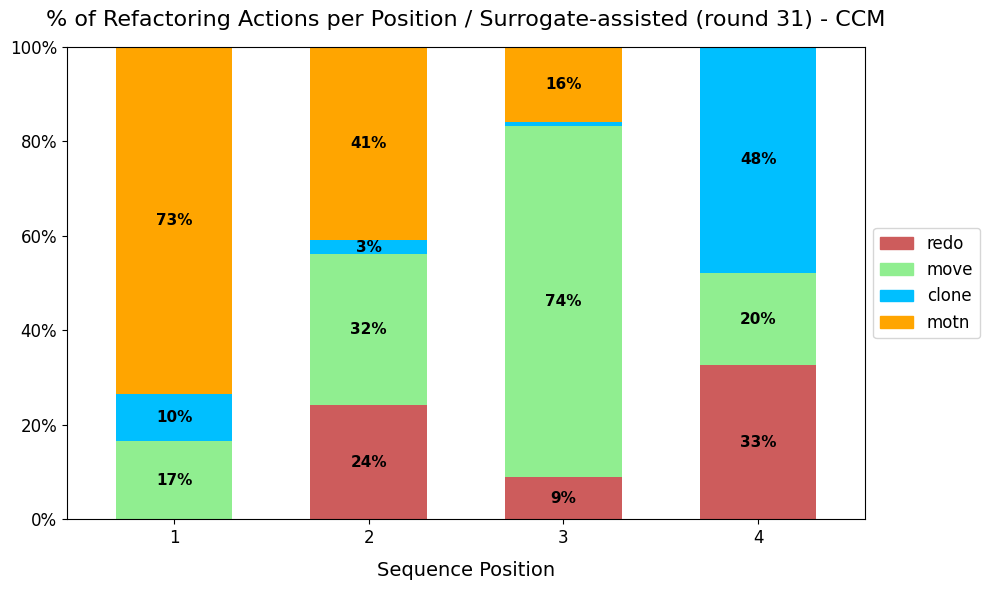

In [14]:
# Running for round 31 - CCM - Surrogate-assisted
plot_stacked_actions_per_position(
    df=run_df1,
    action_types=ref_types,
    colors=colors,
    title='% of Refactoring Actions per Position / Surrogate-assisted (round 31) - CCM',
    figsize=(10, 6),
    label_threshold=0.02,
    ylabel=''
)
plt.show()

<Figure size 1000x600 with 0 Axes>

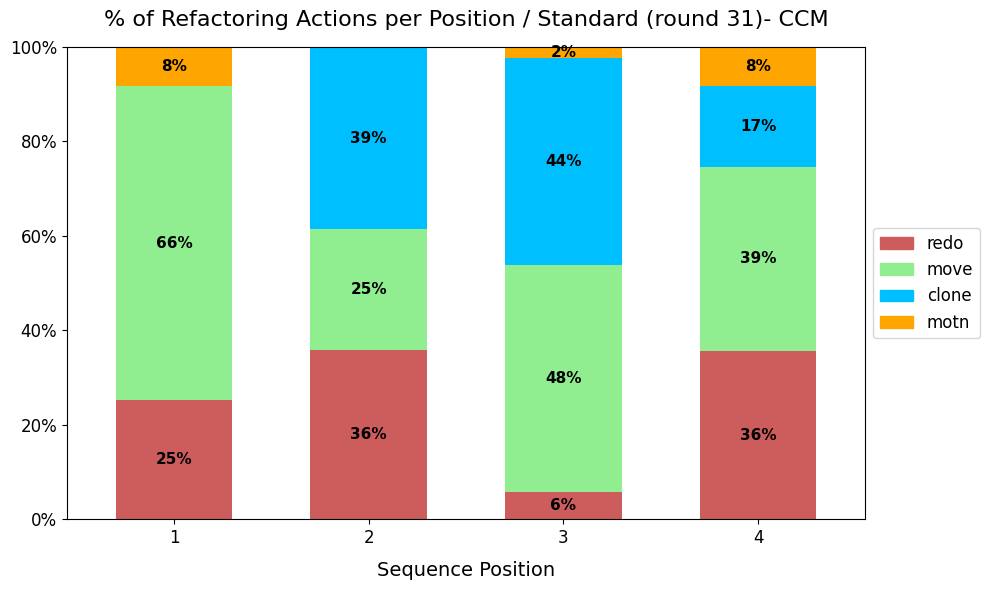

In [15]:
# Running for round 31 - CCM - Standard
plot_stacked_actions_per_position(
    df=run_df2,
    action_types=ref_types,
    colors=colors,
    title='% of Refactoring Actions per Position / Standard (round 31)- CCM',
    figsize=(10, 6),
    label_threshold=0.02,
    ylabel=''
)
plt.show()

Collecting last population for all runs (convergence)

In [16]:
allrounds_df1 = collect_actions_all_runs(n_runs=31, n_populations=102, 
                                         objectives=ccm_objectives,
                                         init_population=101, # process_actions=True,
                                         algorithm='surrogates', path="./nsgaii-ccm-eval-102-surrogate-50")
print(allrounds_df1.shape)

(1488, 5)


In [17]:
allrounds_df2 = collect_actions_all_runs(n_runs=31, n_populations=102, 
                                         objectives=ccm_objectives,
                                         init_population=101, # process_actions=True,
                                         algorithm='standard', path="./nsgaii-ccm-eval-102-surrogate-false")
print(allrounds_df2.shape)

(1488, 5)


<Figure size 1000x600 with 0 Axes>

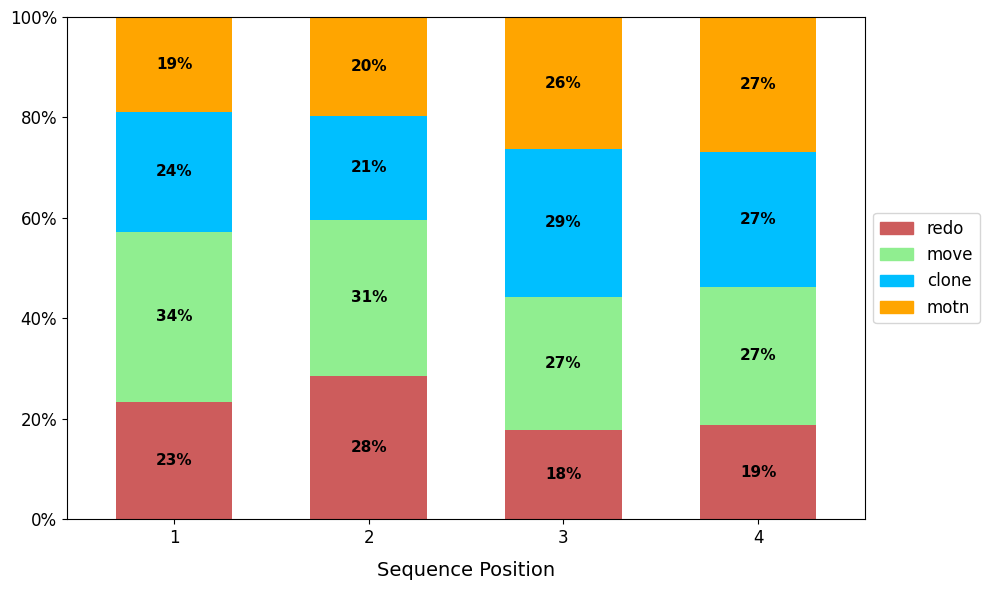

In [18]:
# Running for all rounds but last population - CCM - Surrogates
plot_stacked_actions_per_position(
    df=allrounds_df1,
    action_types=ref_types,
    colors=colors,
    title=None, #'% of Refactoring Actions per Position / Surrogate-assisted (all rounds, last population) - CCM',
    figsize=(10, 6),
    label_threshold=0.02,
    ylabel=''
)
plt.show()

<Figure size 1000x600 with 0 Axes>

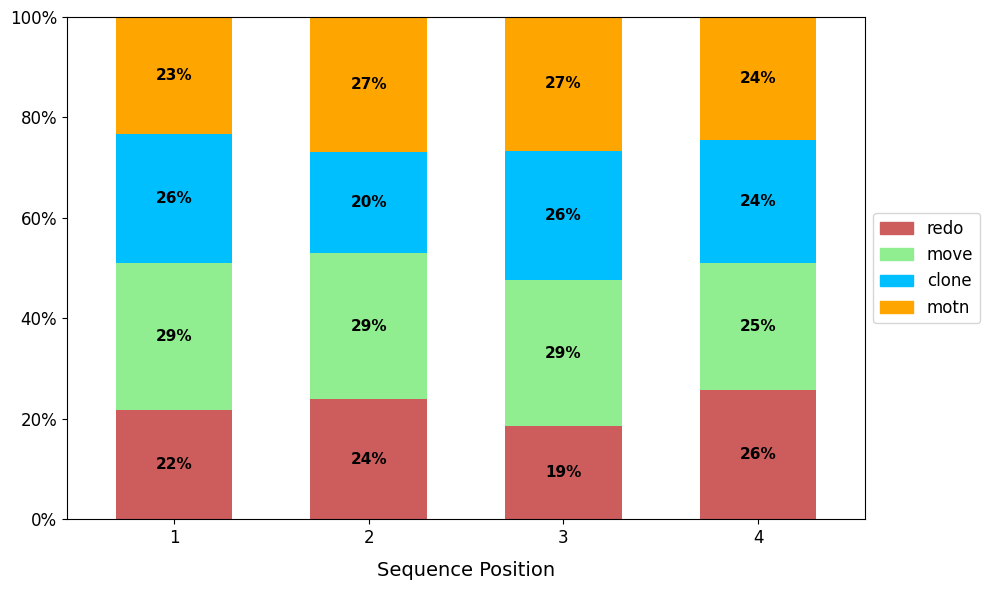

In [19]:
# Running for all rounds but last population - CCM - Standard
plot_stacked_actions_per_position(
    df=allrounds_df2,
    action_types=ref_types,
    colors=colors,
    title=None, #'% of Refactoring Actions per Position / Standard (all rounds, last population)- CCM',
    figsize=(10, 6),
    label_threshold=0.02,
    ylabel=''
)
plt.show()

Collecting all refactoring actions

In [20]:
allrounds_sequences_df1 = collect_actions_all_runs(n_runs=31, n_populations=102, 
                                        objectives=ccm_objectives,
                                        process_actions=False, # init_population=101, 
                                        algorithm='surrogates', path="./nsgaii-ccm-eval-102-surrogate-50")
allrounds_sequences_df1['actions'] = allrounds_sequences_df1['actions'].apply(lambda x: [action.split('__')[0] for action in x])
print(allrounds_sequences_df1.shape)
allrounds_sequences_df1.head()

(37944, 5)


,solID,actions,run,population,algorithm
0,10,"[clone, moc, clone, mcnn]",1,1,surrogates
1,9,"[clone, clone, clone, moncnn]",1,1,surrogates
2,8,"[moc, clone, moc, moncnn]",1,1,surrogates
3,7,"[moc, mcnn, clone, clone]",1,1,surrogates
4,5,"[clone, moc, mcnn, moncnn]",1,1,surrogates


In [21]:
allrounds_sequences_df2 = collect_actions_all_runs(n_runs=31, n_populations=102, 
                                        objectives=ccm_objectives,
                                        process_actions=False, # init_population=101, 
                                        algorithm='standard', path="./nsgaii-ccm-eval-102-surrogate-false")
allrounds_sequences_df2['actions'] = allrounds_sequences_df2['actions'].apply(lambda x: [action.split('__')[0] for action in x])
print(allrounds_sequences_df2.shape)
allrounds_sequences_df2.head()

(37944, 5)


,solID,actions,run,population,algorithm
0,11,"[mcnn, moncnn, moncnn, moncnn]",1,1,standard
1,10,"[moc, moc, mcnn, moc]",1,1,standard
2,9,"[mcnn, mcnn, moc, mcnn]",1,1,standard
3,8,"[clone, moncnn, clone, mcnn]",1,1,standard
4,7,"[moncnn, moncnn, mcnn, moncnn]",1,1,standard


In [22]:
sequences1 = set(['$$'.join(x) for x in allrounds_sequences_df1['actions'].tolist()])
sequences2 = set(['$$'.join(x) for x in allrounds_sequences_df2['actions'].tolist()])
print(f"Number of unique sequences in Surrogate-assisted: {len(sequences1)}")
print(f"Number of unique sequences in Standard: {len(sequences2)}")

# Intersection
common_sequences = sequences1.intersection(sequences2)
print(f"Number of common sequences between both approaches: {len(common_sequences)}")

Number of unique sequences in Surrogate-assisted: 180
Number of unique sequences in Standard: 190
Number of common sequences between both approaches: 135


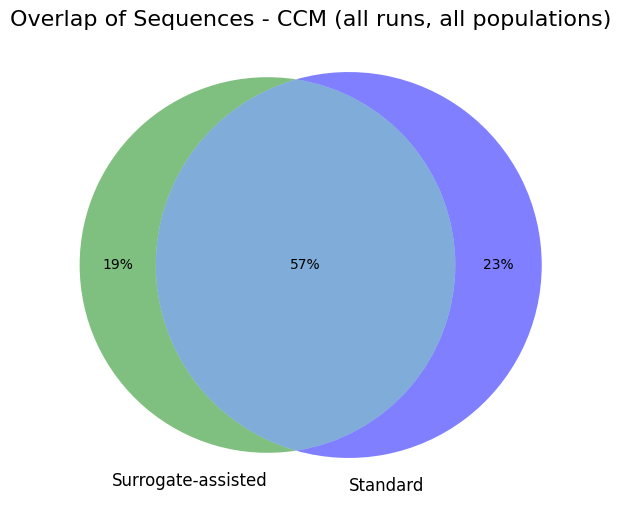

In [23]:
# Draw a Venn diagram to show the overlap between both sets of sequences
# Show the numbers as percentage of total unique sequences

plt.figure(figsize=(8, 6))
total = len(sequences1.union(sequences2))
venn2(subsets = (len(sequences1) - len(common_sequences), 
                    len(sequences2) - len(common_sequences), 
                    len(common_sequences)),
        set_labels = ('Surrogate-assisted', 'Standard'),
        set_colors = ('green', 'blue'),
        subset_label_formatter=lambda x: f"{(x/total):1.0%}",
        alpha = 0.5)
# plt.title('Overlap of Refactoring Action Sequences between Approaches', fontsize=16)
plt.title('Overlap of Sequences - CCM (all runs, all populations)', fontsize=16)
plt.show()

---

## **TTBS**

Collecting all populations for run 31 (last)

In [24]:
run_df1 = collect_actions_per_run(run=31, n_populations=102, 
                                  # process_actions=True, # init_population=101, 
                                  objectives=ttbs_objectives_seq,
                                  algorithm='surrogates', 
                                  path="nsgaii-ttbs-eval-102-surrogate-50_seq")
print(run_df1.shape)
run_df1.head()

(4896, 5)


,run,population,action_type,position,algorithm
0,31,1,redo,0,surrogates
1,31,1,redo,0,surrogates
2,31,1,redo,0,surrogates
3,31,1,redo,1,surrogates
4,31,1,redo,2,surrogates


In [25]:
run_df2 = collect_actions_per_run(run=31, n_populations=102, 
                                  # process_actions=True, # init_population=101, 
                                  objectives=ttbs_objectives_std,
                                  algorithm='standard', 
                                  path="nsgaii-ttbs-eval-102-surrogate-false")
print(run_df2.shape)
run_df2.head()

(4896, 5)


,run,population,action_type,position,algorithm
0,31,1,redo,0,standard
1,31,1,redo,0,standard
2,31,1,redo,0,standard
3,31,1,redo,0,standard
4,31,1,redo,0,standard


<Figure size 1000x600 with 0 Axes>

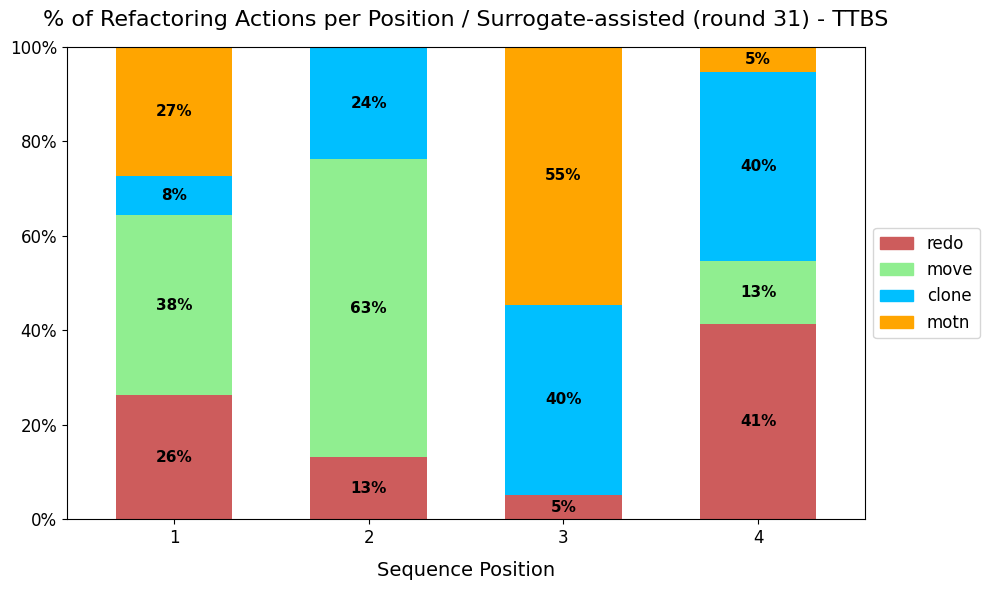

In [26]:
# Running for round 31 - TTBS - Surrogate-assisted
plot_stacked_actions_per_position(
    df=run_df1,
    action_types=ref_types,
    colors=colors,
    title='% of Refactoring Actions per Position / Surrogate-assisted (round 31) - TTBS',
    figsize=(10, 6),
    label_threshold=0.02,
    ylabel=''
)
plt.show()

<Figure size 1000x600 with 0 Axes>

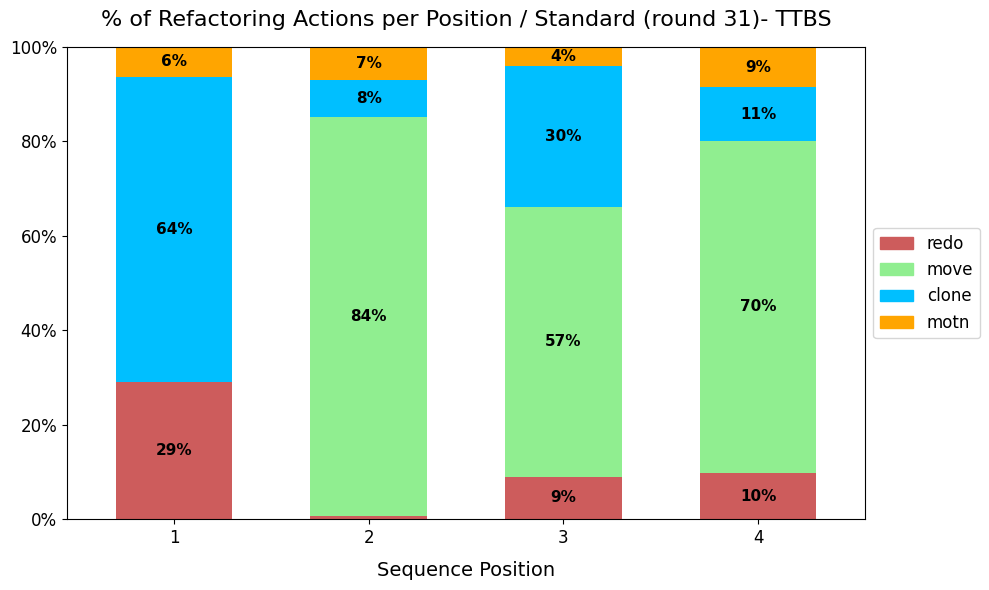

In [27]:
# Running for round 31 - TTBS - Standard
plot_stacked_actions_per_position(
    df=run_df2,
    action_types=ref_types,
    colors=colors,
    title='% of Refactoring Actions per Position / Standard (round 31)- TTBS',
    figsize=(10, 6),
    label_threshold=0.02,
    ylabel=''
)
plt.show()

Collecting last population for all runs (convergence)

In [28]:
allrounds_df1 = collect_actions_all_runs(n_runs=31, n_populations=102, 
                                         objectives=ttbs_objectives_seq,
                                         init_population=101, # process_actions=True,
                                         algorithm='surrogates', path="./nsgaii-ttbs-eval-102-surrogate-50_seq")
print(allrounds_df1.shape)

(1488, 5)


In [29]:
allrounds_df2 = collect_actions_all_runs(n_runs=31, n_populations=102, 
                                         objectives=ttbs_objectives_std,
                                         init_population=101, # process_actions=True,
                                         algorithm='standard', path="./nsgaii-ttbs-eval-102-surrogate-false")
print(allrounds_df2.shape)

(1476, 5)


<Figure size 1000x600 with 0 Axes>

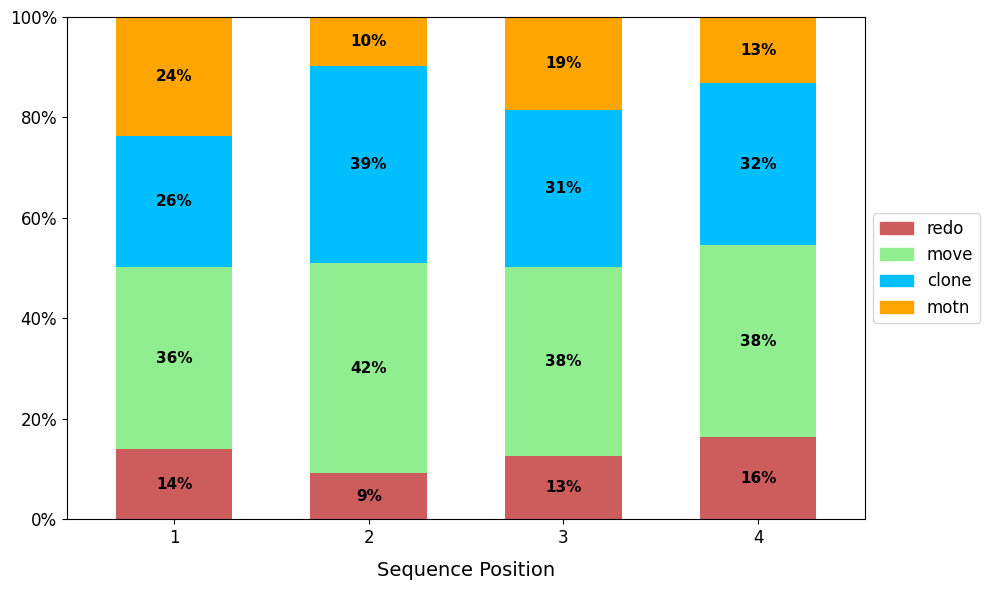

In [30]:
# Running for all rounds but last population - TTBS - Surrogates
plot_stacked_actions_per_position(
    df=allrounds_df1,
    action_types=ref_types,
    colors=colors,
    title=None, #'% of Refactoring Actions per Position / Surrogate-assisted (all rounds, last population) - TTBS',
    figsize=(10, 6),
    label_threshold=0.02,
    ylabel=''
)
plt.show()

<Figure size 1000x600 with 0 Axes>

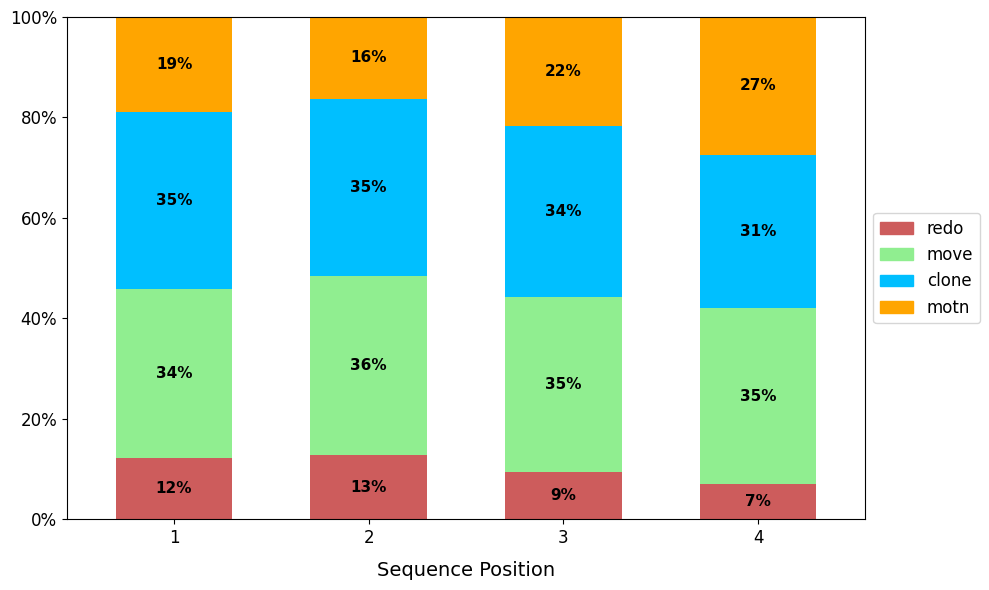

In [31]:
# Running for all rounds but last population - TTBS - Standard
plot_stacked_actions_per_position(
    df=allrounds_df2,
    action_types=ref_types,
    colors=colors,
    title=None, #'% of Refactoring Actions per Position / Standard (all rounds, last population)- TTBS',
    figsize=(10, 6),
    label_threshold=0.02,
    ylabel=''
)
plt.show()

Collecting all refactoring actions

In [32]:
allrounds_sequences_df1 = collect_actions_all_runs(n_runs=31, n_populations=102, 
                                        objectives=ttbs_objectives_seq,
                                        process_actions=False, # init_population=101, 
                                        algorithm='surrogates', path="./nsgaii-ttbs-eval-102-surrogate-50_seq")
allrounds_sequences_df1['actions'] = allrounds_sequences_df1['actions'].apply(lambda x: [action.split('__')[0] for action in x])
print(allrounds_sequences_df1.shape)
allrounds_sequences_df1.head()

(37944, 5)


,solID,actions,run,population,algorithm
0,8,"[moc, clone, clone, clone]",1,1,surrogates
1,7,"[mcnn, mcnn, mcnn, mcnn]",1,1,surrogates
2,4,"[clone, moncnn, clone, mcnn]",1,1,surrogates
3,2,"[clone, moncnn, moncnn, moc]",1,1,surrogates
4,1,"[moncnn, clone, moc, clone]",1,1,surrogates


In [33]:
allrounds_sequences_df2 = collect_actions_all_runs(n_runs=31, n_populations=102, 
                                        objectives=ttbs_objectives_std,
                                        process_actions=False, # init_population=101, 
                                        algorithm='standard', path="./nsgaii-ttbs-eval-102-surrogate-false")
allrounds_sequences_df2['actions'] = allrounds_sequences_df2['actions'].apply(lambda x: [action.split('__')[0] for action in x])
print(allrounds_sequences_df2.shape)
allrounds_sequences_df2.head()

(37941, 5)


,solID,actions,run,population,algorithm
0,11,"[moncnn, mcnn, moncnn, moncnn]",1,1,standard
1,10,"[mcnn, clone, moc, clone]",1,1,standard
2,8,"[moc, moc, moc, mcnn]",1,1,standard
3,7,"[moc, mcnn, moncnn, mcnn]",1,1,standard
4,6,"[moc, clone, clone, mcnn]",1,1,standard


In [34]:
sequences1 = set(['$$'.join(x) for x in allrounds_sequences_df1['actions'].tolist()])
sequences2 = set(['$$'.join(x) for x in allrounds_sequences_df2['actions'].tolist()])
print(f"Number of unique sequences in Surrogate-assisted: {len(sequences1)}")
print(f"Number of unique sequences in Standard: {len(sequences2)}")

# Intersection
common_sequences = sequences1.intersection(sequences2)
print(f"Number of common sequences between both approaches: {len(common_sequences)}")

Number of unique sequences in Surrogate-assisted: 191
Number of unique sequences in Standard: 211
Number of common sequences between both approaches: 161


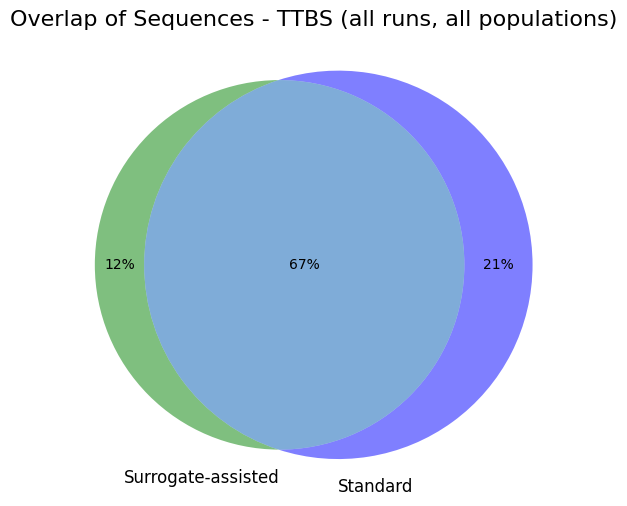

In [35]:
# Draw a Venn diagram to show the overlap between both sets of sequences
# Show the numbers as percentage of total unique sequences

plt.figure(figsize=(8, 6))
total = len(sequences1.union(sequences2))
venn2(subsets = (len(sequences1) - len(common_sequences), 
                    len(sequences2) - len(common_sequences), 
                    len(common_sequences)),
        set_labels = ('Surrogate-assisted', 'Standard'),
        set_colors = ('green', 'blue'),
        subset_label_formatter=lambda x: f"{(x/total):1.0%}",
        alpha = 0.5)
# plt.title('Overlap of Refactoring Action Sequences between Approaches', fontsize=16)
plt.title('Overlap of Sequences - TTBS (all runs, all populations)', fontsize=16)
plt.show()

---